# Lab Program 1
## Probability Computation, Conditional Probability & Bayes' Theorem: Simulate and visualize probability experiments, verify addition and multiplication rules, compute conditional probabilities, and apply Bayes' Theorem to real-world classification scenarios. (CO1)

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import itertools

In [2]:
np.random.seed(42)

# --- PART 1A: Classical Probability --- 
coin_space = ['H', 'T']
two_coin = list(itertools.product(coin_space, coin_space))
print('Sample Space:', two_coin)

Sample Space: [('H', 'H'), ('H', 'T'), ('T', 'H'), ('T', 'T')]


In [3]:
two_heads = [s for s in two_coin if s.count('H') == 2]
P_2H = len(two_heads) / len(two_coin)
print(f'P(2 Heads) = {P_2H}')

P(2 Heads) = 0.25


## PART 1A — Dice Addition Rule
### Now the program demonstrates the addition rule of probability.

In [4]:
# Dice - Addition Rule
dice = list(range(1, 7))
A = [x for x in dice if x % 2 == 0]   # Even
B = [x for x in dice if x > 3]          # Greater than 3
P_A = len(A)/6;  P_B = len(B)/6
P_AB = len(set(A)&set(B))/6
print(f'P(A∪B) = P(A)+P(B)-P(A∩B) = {P_A+P_B-P_AB:.4f}')

P(A∪B) = P(A)+P(B)-P(A∩B) = 0.6667


## PART 1B: Empirical Probability
### Now the program moves from theoretical probability to experimental probability.

In [5]:
# --- PART 1B: Empirical Convergence ---
for n in [10, 100, 1000, 10000]:
    tosses = np.random.binomial(1, 0.5, n)
    print(f'n={n:>6}: P(H)={tosses.mean():.4f}')

n=    10: P(H)=0.6000
n=   100: P(H)=0.4500
n=  1000: P(H)=0.5050
n= 10000: P(H)=0.4940


## PART 1C: Bayes' Theorem
### This is the most important statistical section of the program.
### The example considers a medical diagnostic test.

In [6]:
# --- PART 1C: Bayes' Theorem ---
P_Disease = 0.01    # Only 1% of the population has the disease.
P_Pos_D   = 0.99    # Sensitivity - If a person has the disease, the probability that the test is positive is 99%.
P_Pos_ND  = 0.05    # False Positive Rate - If a person does NOT have the disease, there is still a 5% probability that the test is positive.


# Total Probability
P_Pos = P_Pos_D*P_Disease + P_Pos_ND*(1-P_Disease)
# Bayes' Theorem
P_D_Pos = (P_Pos_D * P_Disease) / P_Pos
print(f'P(Disease | Positive) = {P_D_Pos:.4f} ({P_D_Pos*100:.2f}%)')

P(Disease | Positive) = 0.1667 (16.67%)


# PART 2: Visualization
## The final section demonstrates the Law of Large Numbers visually.

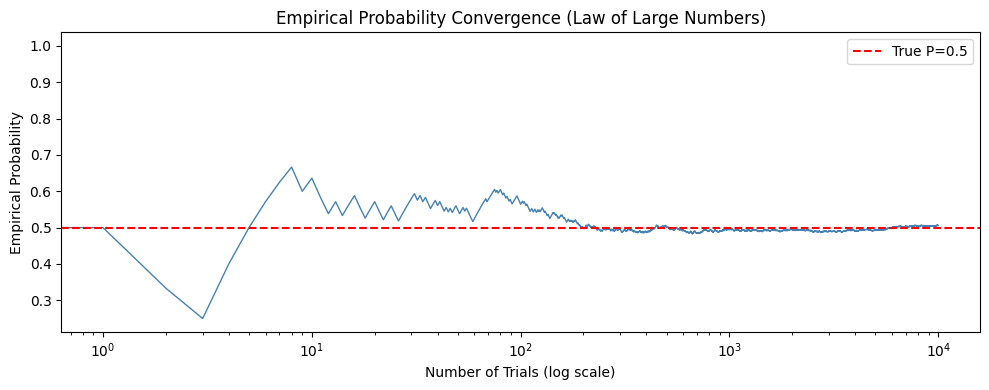

In [7]:
# --- VISUALIZATION ---
# Empirical convergence plot
n_total = 10000
tosses  = np.random.binomial(1, 0.5, n_total)
emp_prob = [tosses[:i].mean() for i in range(1, n_total+1)]
plt.figure(figsize=(10,4))
plt.plot(emp_prob, color='steelblue', linewidth=1)
plt.axhline(0.5, color='red', linestyle='--', label='True P=0.5')
plt.xscale('log')
plt.title('Empirical Probability Convergence (Law of Large Numbers)')
plt.xlabel('Number of Trials (log scale)')
plt.ylabel('Empirical Probability')
plt.legend(); plt.tight_layout(); plt.show()

## Inference from the Graph
### The graph demonstrates the Law of Large Numbers through repeated simulation of a fair coin toss.
- The red dashed line at 0.5 represents the theoretical probability of obtaining Heads.
- For a small number of trials, the empirical probability fluctuates significantly, ranging approximately from 0.25 to 0.67.
- As the number of trials increases, these fluctuations gradually decrease.
- After a few hundred trials, the empirical probability becomes increasingly close to 0.5.
- At around 1,000–10,000 trials, the curve remains very close to the theoretical probability of 0.5.
- Therefore, the graph confirms that as the number of independent trials increases, the empirical probability converges toward the theoretical probability.

The graph clearly demonstrates the Law of Large Numbers. For a small number of trials, the empirical probability of obtaining Heads varies considerably due to random fluctuations. However, as the number of trials increases, the empirical probability gradually converges toward the theoretical probability of 0.5. Hence, a larger number of trials provides a more reliable estimate of the true probability.

# Exercise Questions

1. Coin Toss Probability
Write a Python program to generate the sample space for three coin tosses and calculate the probability of:
- a) Getting exactly 3 Heads
- b) Getting exactly 2 Heads
- c) Getting at least 1 Head
Hint: Use itertools.product().

2. Dice Probability
Write a Python program to calculate the probability of getting:
- a) An even number
- b) An odd number
- c) A number greater than 4
- d) A number less than or equal to 3
Use the sample space of a single die.

3. Two-Dice Experiment
Generate the sample space for rolling two dice and calculate the probability that:
- a) The sum is 7
- b) The sum is greater than 8
- c) Both dice show the same number
- d) At least one die shows 6
Hint: Use itertools.product(range(1,7), range(1,7)).